# 02 · Повторная вложенная CV и Grid Search

## tl;dr

Подбор шести семейств выполнен по group-balanced log loss с эвристикой One-SE. Внешняя оценка — 3 повтора ×5 фолдов, внутри — 3 фолда. Параметры, семья и калибровка выбираются без внешних меток. Все 2126 сегментов уже известны исследователю; это исправленный exploratory benchmark.

Исправленная процедура: mean group-balanced Macro-F1 **0.855**, recall suspect **70.5%**, recall pathologic **82.6%**. Это средние метрики трёх повторов, не точность финального full-data fit.


## Context & Methods
### Key Assumptions
Первичная метрика подбора — log loss с суммарным весом 1 на префикс. One-SE используется как эвристика простоты, не CI зависимых фолдов. Все 6 семейств оценены на одних внешних группах. Отдельная selected_procedure выбирает семью только внутри fit, поэтому её outer score оценивает выбор, а не объявленный задним числом максимум.


In [3]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
REVIEW=ROOT/'research/reviews/ctg_20261017'
UCI=ROOT/'research/experiments/ctg_uci/reviewed_v3'
JNU=ROOT/'research/experiments/jnu_ctg/reviewed_v2'
FIGURES=REVIEW/'figures';FIGURES.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth',170)
sns.set_theme(style='whitegrid',font_scale=1.0)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False})
COLORS={'linear':'#009e73','spline':'#d55e00','catboost':'#0072b2'}
def save_show(name):
    plt.gcf().savefig(FIGURES/name,dpi=140,bbox_inches='tight')
    plt.show()


## Data · запуск исправленной процедуры

In [5]:
from src.training.ctg_prefix_benchmark import run
metrics=run()
protocol=json.loads((UCI/'protocol.json').read_text())
display(pd.Series({k:v for k,v in protocol.items() if k not in ['input_sha256','cat_grid','logistic_grid']}).to_frame('protocol'))
display(metrics.groupby('family')[['group_macro_f1','group_log_loss','group_recall_suspect','group_recall_path','segment_macro_f1']].agg(['mean','std']).round(4))
display(pd.read_csv(UCI/'outer_class_support.csv'))
print('Группа может содержать несколько классов: group counts разных классов не складываются.')


Группа может содержать несколько классов: group counts разных классов не складываются.


,protocol
fingerprint,3ba84fa0b44c8b40fdc3808ded0b94edce484933f16b138d9fa130d71c6c1bc2
environment,"{'numpy': '2.4.6', 'pandas': '2.3.3', 'scikit-learn': '1.9.1', 'catboost': '1.2.10'}"
grouping,initials-like prefix proxy; S+digits kept; union exact feature duplicates; identity unverified
repeats,3
outer,5
inner,3
selector,"minimum group-balanced log loss, one-SE parsimony heuristic within each fit"
calibration,fixed temperature on current fit-side selected-configuration OOF; outer labels never enter calibration
decision,argmax; no posthoc threshold tuning
sample_weight,"1/current-fit-prefix-segment-count, normalized mean 1"


group_macro_f1          ... segment_macro_f1        
                             mean     std  ...             mean     std
family                                     ...                         
A_multiclass               0.8499  0.0122  ...           0.8496  0.0019
B_balanced                 0.8423  0.0187  ...           0.8336  0.0102
B_sqrt                     0.8574  0.0094  ...           0.8454  0.0046
C_ovr                      0.8651  0.0174  ...           0.8611  0.0080
D_hierarchy                0.8417  0.0230  ...           0.8477  0.0098
logistic                   0.7169  0.0106  ...           0.7308  0.0061
selected_procedure         0.8548  0.0185  ...           0.8529  0.0015

[7 rows x 10 columns]

,repetition,outer_fold,NSP,segments,proxy_groups
0,0,0,1,331,34
1,0,0,2,59,11
2,0,0,3,36,7
3,0,1,1,333,33
4,0,1,2,58,11
5,0,1,3,35,7
6,0,2,1,331,33
7,0,2,2,59,11
8,0,2,3,36,7
9,0,3,1,331,34


## Results · метрики трёх повторов

Полные параметры всех фолдов и кандидатов сохранены в JSON, таблица выше ограничена первыми 18 строками.


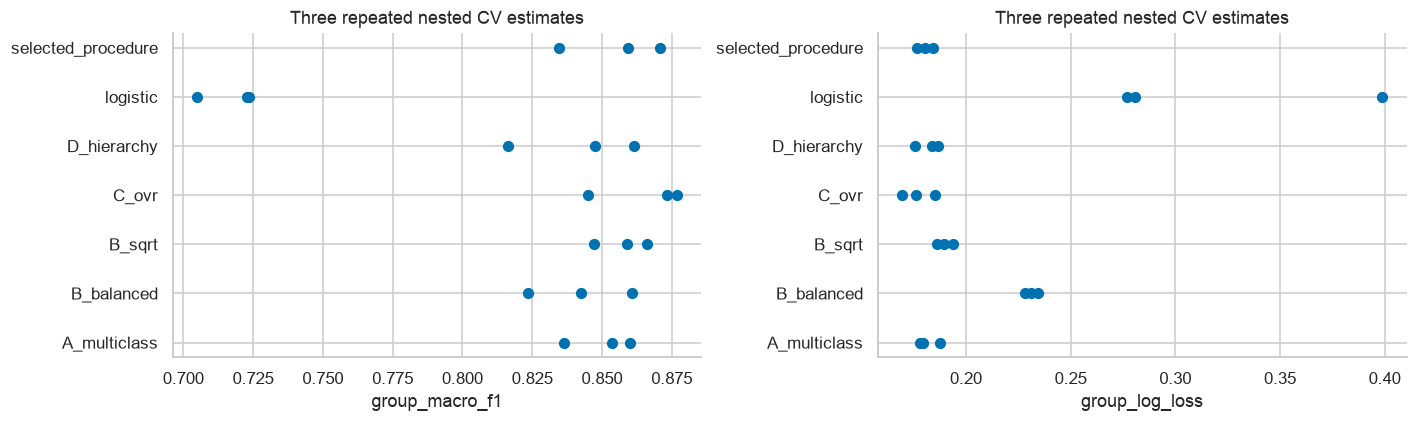

,repetition,outer_fold,family,params,mean_loss,one_se_cutoff,selected_family
0,0,0,logistic,{'C': 0.1},0.288120,0.296388,D_hierarchy
1,0,0,A_multiclass,"{'depth': 3, 'l2_leaf_reg': 10, 'learning_rate': 0.1, 'iterations': 300}",0.209601,0.219141,D_hierarchy
2,0,0,B_sqrt,"{'depth': 3, 'l2_leaf_reg': 10, 'learning_rate': 0.1, 'iterations': 300}",0.215240,0.215817,D_hierarchy
3,0,0,B_balanced,"{'depth': 3, 'l2_leaf_reg': 3, 'learning_rate': 0.1, 'iterations': 300}",0.243134,0.244883,D_hierarchy
4,0,0,C_ovr,"{'depth': 3, 'l2_leaf_reg': 10, 'learning_rate': 0.1, 'iterations': 300}",0.180155,0.202961,D_hierarchy
5,0,0,D_hierarchy,"{'depth': 3, 'l2_leaf_reg': 10, 'learning_rate': 0.03, 'iterations': 300}",0.195726,0.196788,D_hierarchy
6,0,1,logistic,{'C': 0.1},0.292511,0.317701,A_multiclass
7,0,1,A_multiclass,"{'depth': 3, 'l2_leaf_reg': 10, 'learning_rate': 0.1, 'iterations': 300}",0.197308,0.219778,A_multiclass
8,0,1,B_sqrt,"{'depth': 3, 'l2_leaf_reg': 10, 'learning_rate': 0.1, 'iterations': 300}",0.203926,0.234400,A_multiclass
9,0,1,B_balanced,"{'depth': 3, 'l2_leaf_reg': 3, 'learning_rate': 0.1, 'iterations': 300}",0.235095,0.250809,A_multiclass


In [7]:
families=list(metrics.family.unique());fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,col in zip(axes,['group_macro_f1','group_log_loss']):
    for i,family in enumerate(families):
        z=metrics[metrics.family==family];ax.scatter(z[col],np.full(len(z),i),color='#0072b2',s=40)
    ax.set(yticks=range(len(families)),yticklabels=families,xlabel=col,title='Three repeated nested CV estimates')
fig.tight_layout();save_show('uci02_repeated_nested_cv.png')
choices=pd.read_json(UCI/'nested_choices.json')
display(choices[['repetition','outer_fold','family','params','mean_loss','one_se_cutoff','selected_family']].head(18))
print('Полные параметры всех фолдов и кандидатов сохранены в JSON, таблица выше ограничена первыми 18 строками.')


### Конечная сетка и выбор семейства

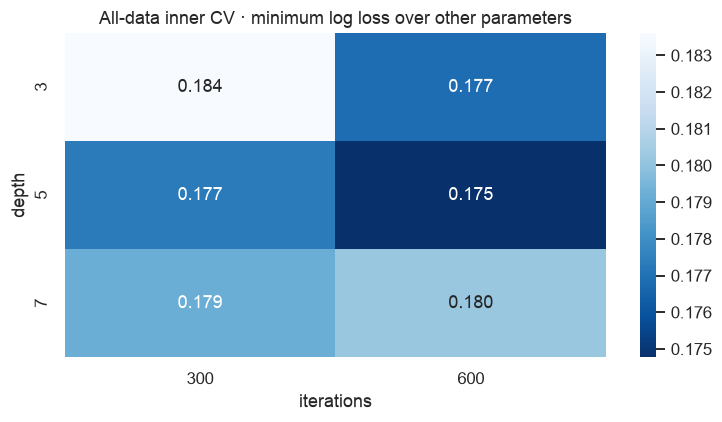

,outer fits
selected_family,
A_multiclass,10
D_hierarchy,3
C_ovr,1
B_sqrt,1


In [9]:
grid=pd.read_json(UCI/'final_grid_A_multiclass.json')
flat=pd.concat([grid.drop(columns='params'),pd.json_normalize(grid.params)],axis=1)
heat=flat.groupby(['depth','iterations']).mean_loss.min().unstack()
fig,ax=plt.subplots(figsize=(7,4));sns.heatmap(heat,annot=True,fmt='.3f',cmap='Blues_r',ax=ax)
ax.set_title('All-data inner CV · minimum log loss over other parameters')
fig.tight_layout();save_show('uci02_grid_logloss.png')
display(choices[['repetition','outer_fold','selected_family']].drop_duplicates().selected_family.value_counts().rename('outer fits').to_frame())


## Takeaways

UCI используется как benchmark экспертных классов. Префикс — прокси независимого источника, не подтверждённый ID пациентки. Все данные ранее просмотрены: эта ревизия оценивает исправленную процедуру на повторной nested CV, без нового blind-test заявления. Полный разбор 23 замечаний — в [07](07_deep_audit_and_recommendations.ipynb).
